In [63]:
from spectrascope.ss_classification import *
from spectrascope.plot_spectral_features import PlotSpectralFeatures as psf
from dataclasses import dataclass
import pathlib
import contextlib

In [64]:
@dataclass
class SpecMetadata:
    name: str
    xaxis_label: str
    yaxis_label: str
    xaxis: np.ndarray


@dataclass
class SpectraScopeInput:
    X: np.ndarray | list[np.ndarray]
    y: np.ndarray
    specnames: list[str]
    yname: str
    spec_metadata: dict[str, SpecMetadata] = None

In [65]:
X = []
y = None
yname = None
specnames = []
spec_metadata = {}
for csv_upload in ["/Users/chrisfajardo/Downloads/sample.csv"]:
    csv_df = pd.read_csv(csv_upload, index_col=0)
    curr_X = csv_df.iloc[:-1, :-1].to_numpy()
    curr_y = csv_df.iloc[:-1, -1].to_numpy()
    curr_y_name = csv_df.columns[-1]
    curr_xaxis = csv_df.iloc[-1, :-1].to_numpy()
    curr_xaxis_label = csv_df.index[-1]
    curr_specname = pathlib.Path(csv_upload).name.removesuffix(".csv")

    X.append(curr_X)
    if y is not None and not np.array_equal(y, curr_y):
        st.error("all datasets must have same y data")
        st.stop()
    y = curr_y
    yname = curr_y_name
    specnames.append(curr_specname)
    spec_metadata[curr_specname] = SpecMetadata(
        name=curr_specname,
        xaxis_label=curr_xaxis_label,
        yaxis_label=curr_y_name,
        xaxis=curr_xaxis,
    )
spec_input = SpectraScopeInput(
    X=X, y=y, specnames=specnames, yname=yname, spec_metadata=spec_metadata
)
data = SpectraScope(X=spec_input.X, y=spec_input.y, specnames=spec_input.specnames, yname=spec_input.yname)
for name in data.specnames:
    data.add_x_axis(specname=name, value=spec_input.spec_metadata[name].xaxis)

no random seed selected, when splitting data, will always give different split
saving to /examples/models, change save_path kwarg if youd like to change


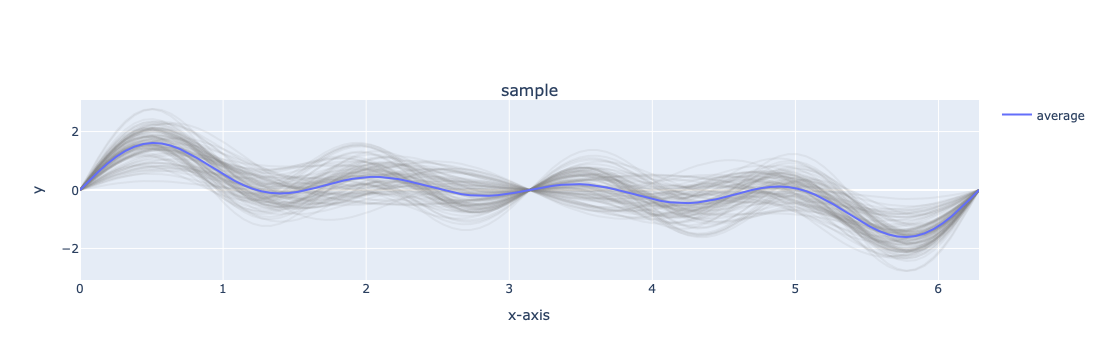

In [66]:
fig1 = make_subplots(
    rows=1,
    cols=len(spec_input.specnames),
    subplot_titles=data.specnames,
    horizontal_spacing=0.15,
)
axis_dict = {}
for i, spec in enumerate(data.specnames):
    xaxis_label, yaxis_label = (
        spec_input.spec_metadata[spec].xaxis_label,
        spec_input.spec_metadata[spec].yaxis_label,
    )
    axis_dict[spec] = (xaxis_label, yaxis_label)
    x = getattr(data, f"{spec}_xaxis")
    y = getattr(data, f"{spec}")
    plotter = psf(
        xaxis=x,
        arr=y,
        xaxis_label=xaxis_label,
        yaxis_label=yaxis_label,
        name="",
        fig=fig1,
        row=1,
        col=i + 1,
    )
    plotter.plot_raw_spec()
fig1

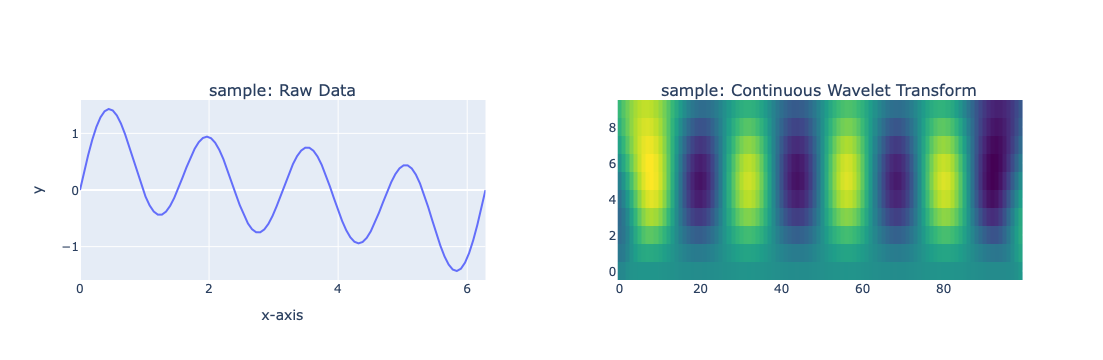

In [67]:
pretty_names = {
    "Raw Data": "pointwise_features",
    "Principal Component Analysis": "pca",
    "Fourier Transform": "fft_features",
    "Cumulative Distribution Function": "cdf",
    "Agglomerative Clustering": "featureagg",
    "Continuous Wavelet Transform": "cwt",
    "Polynomial Fitting": "polynomial_featuresall",
    "T-distributed Stochastic Neighbor Embedding": "tsne",
}

kwargs_dict = {
    "pca": {
        "mode": "markers",
        "marker": dict(color=y, colorscale="Viridis"),
    },  # , showscale=True, colorbar=dict(len=0.3, x=0.3, y=0.5))}
    "cwt": {
        "colorscale": "Viridis",
        "showscale": False,
    },  # ,'colorbar':dict(len=0.3, x=1, y=0.85)}
    "cdf": {},
    "polynomial_featuresall": {},
    "featureagg": {
        "mode": "markers",
        "marker": dict(color=y, colorscale="Viridis"),
    },  # , showscale=True, colorbar=dict(len=0.3, x=0.6, y=0.5))}
    "fft_features": {},
    "pointwise_features": {},
    "tsne": {"mode": "markers", "marker": dict(color=y, colorscale="Viridis")},
}

pretty_features = ["Raw Data", "Continuous Wavelet Transform"]
features = [pretty_names[f] for f in pretty_features]
nfeats = len(features)
spec = "sample"

fig = make_subplots(
        rows=1,
        cols=nfeats,
        subplot_titles=[f"{spec}: {p}" for p in pretty_features],
        horizontal_spacing=0.14,
    )
for i, feat in enumerate(features):
    kwargs = kwargs_dict[feat]
    if "fft" in feat or "pointwise" in feat:
        data.add_spectral_feature(
            spec, feat, xrange=getattr(data, f"{spec}_xaxis")
        )
        if "pointwise" in feat:
            xaxis_label, yaxis_label = axis_dict[spec]
        else:
            xaxis_label = "Frequency"
            yaxis_label = "FFT"
    else:
        data.add_spectral_feature(spec, feat)
        if "cdf" in feat:
            xaxis_label, yaxis_label = axis_dict[spec]
            yaxis_label = "Cumulative Intensity"
        elif "polynomial" in feat:
            xaxis_label = "Feature Index"
            yaxis_label = "Polynomial Coefficientr"

        else:
            xaxis_label = ""
            yaxis_label = ""

    arr = data.__getattribute__(spec + "_" + feat)
    if feat == "pca" or feat == "featureagg" or feat == "tsne":
        xaxis_label = "Component 1"
        yaxis_label = "Component 2"
    else:
        arr = arr[0].ravel()

    xaxis = getattr(data, f"{spec}_xaxis")
    temp = psf(
        arr,
        xaxis=xaxis,
        fig=fig,
        row=1,
        col=i + 1,
        xaxis_label=xaxis_label,
        yaxis_label=yaxis_label,
    )
    getattr(temp, f"plot_{feat}").__call__(showlegend=False, **kwargs)
fig

In [68]:
fit_sk = True
fit_lcen = True
features_selected = []
for spec in specnames:
    for feat in features:
        features_selected.append(spec + "_" + feat)
cross_validate = False
rf_kwargs = {"estimator": RandomForestRegressor()}
sk_kwargs = [rf_kwargs]
lcen_kwargs = {
    "l1_ratio": [0.1, 0.5, 0.9],
    "K_fold": 3,
    "cv_method": "Kfold",
    "alpha": 5,
    "degree": [1],
    "trans_type": "poly",
    "LCEN_cutoff": 4e-3,
    "LCEN_interaction": False,
    "scale_X": True,
    "scale_y": True,
}


@contextlib.contextmanager
def try_fit(attr_name, yattr, model_name):
    try:
        yield
    except Exception as e:
        msg = f"Could not fit {attr_name} with {model_name}. Skipping..."
        print(f"{msg}: {e}")
        if data.best_fits[model_name]:
            data.best_fits[model_name][attr_name + "_" + yattr] = np.nan
        else:
            data.best_fits[model_name] = {attr_name + "_" + yattr: np.nan}

def fit(sk_kwargs, lcen_kwargs, test_size, scale_X, yattr):
    Nm = 0
    if fit_sk:
        Nm = len(sk_kwargs)
    if fit_lcen:
        Nm += 1

    Nf = len(features_selected)

    progress_text = f"Fitting {Nm} model(s) to {Nf} feature(s)"
    N = Nm * Nf
    completed = 0
    fitted_models = []
    for attr_name in features_selected:
        if fit_sk:
            for sk in sk_kwargs:
                model_name = sk["estimator"].__str__().split("()")[0]
                with try_fit(attr_name, yattr, model_name):
                    data.do_sk(
                        attr_name,
                        yattr,
                        test_size,
                        use_pipeline=cross_validate,
                        scale_X=scale_X,
                        **sk,
                    )
                    fitted_models.append(attr_name + "_" + yattr + "_" + model_name)

                completed += 1

        if fit_lcen:
            model_name = "LCEN"
            with try_fit(attr_name, yattr, model_name):
                data.do_LCEN(attr_name, yattr, test_size, None, **lcen_kwargs)
                fitted_models.append(attr_name + "_" + yattr + "_" + model_name)

            completed += 1

    return pd.DataFrame(data.best_fits), fitted_models


best_fit_df, fitted_models = fit(
    sk_kwargs, lcen_kwargs, test_size=0.25, scale_X=True, yattr=yname
)
best_fit_df

Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 18 hyperparameter combinations
Completed model LCEN
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.3116 | Mean relative error = 1.9431
Test set : RMSE = 0.3186 | Mean relative error = 6.7513
already fitted
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 18 hyperparameter combinations
Completed model LCEN
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.3235 | Mean relative error = 3.7647
Test set : RMSE = 0.2797 | Mean relative error = 1.6117


,RandomForestRegressor,LCEN
sample_pointwise_features_y,0.119866,0.101529
sample_cwt_y,0.107485,0.078233


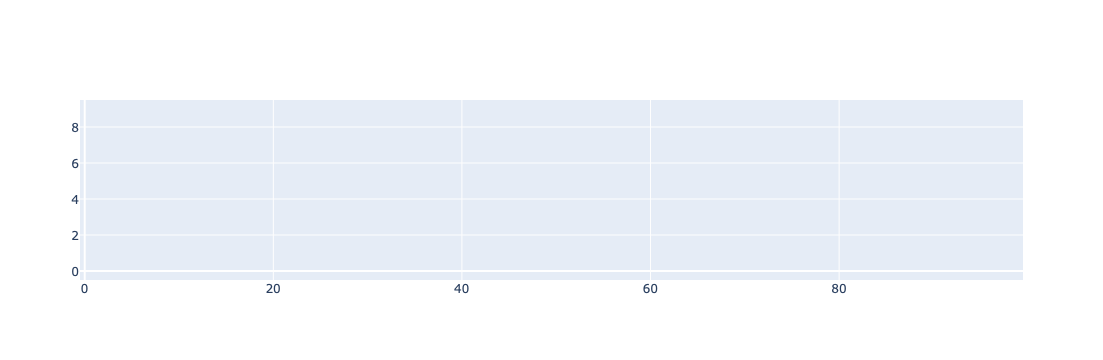

In [126]:
fig_cwt_raw = make_subplots(1, 1)
feature = data.sample_cwt[0].ravel()
xaxis = data.sample_xaxis

temp = psf(
    feature,
    xaxis=xaxis,
    fig=fig_cwt_raw,
    row=1,
    col=1,
    xaxis_label=xaxis_label,
    yaxis_label=yaxis_label,
)
temp.plot_cwt(showlegend=False, colorscale="Viridis", showscale=False)


# widths = len(feature) / len(xaxis)
# widths = int(widths)
# temp = feature.reshape(widths, len(xaxis))
# fig_cwt_raw.add_trace(go.Heatmap(z=temp, **kwargs), row=1, col=1)
# fig_cwt_raw.update_xaxes(title_text=xaxis_label, row=1, col=1)
# fig_cwt_raw.update_yaxes(title_text=yaxis_label, row=1, col=1)


fig_cwt_raw

In [93]:
data.sample_cwt.shape

(100, 1000)

In [112]:
feature_importances = data.sample_cwt_y_RandomForestRegressor["P"].feature_importances_
selected_vals = feature_importances / feature_importances.max()

In [110]:
data.sample_cwt_y_RandomForestRegressor

{'P': RandomForestRegressor(),
 'score': 0.10748469356407477,
 'ypred': array([0.29883022, 0.58486063, 0.23289619, 0.2539476 , 0.80554544,
        0.2693285 , 0.47055856, 0.25772008, 0.46374549, 0.37238153,
        0.28109831, 0.22058727, 0.15437124, 0.28023059, 0.66317629,
        0.25760514, 0.46374077, 0.24889459, 0.20762676, 0.4366012 ,
        0.63178475, 0.66102842, 0.30488286, 0.20899344, 0.64553072]),
 'selected_features': array([376, 389, 641, 227, 687, 765, 684, 590, 268, 329, 332, 711, 542,
        914, 493, 950, 656, 191, 848,   8]),
 'scaled': True,
 'selected_vals': array([5.01503838e-04, 3.76805177e-04, 2.75148977e-04, 1.00706988e-04,
        3.15131396e-05, 8.06170030e-04, 1.48411637e-04, 9.84567237e-05,
        1.95834467e-05, 6.22748058e-05, 1.08224429e-04, 7.31900370e-04,
        1.69170941e-05, 1.19294184e-03, 1.23733251e-04, 1.39459077e-02,
        1.59749382e-05, 3.05778000e-04, 3.83204794e-05, 1.54479134e-05])}

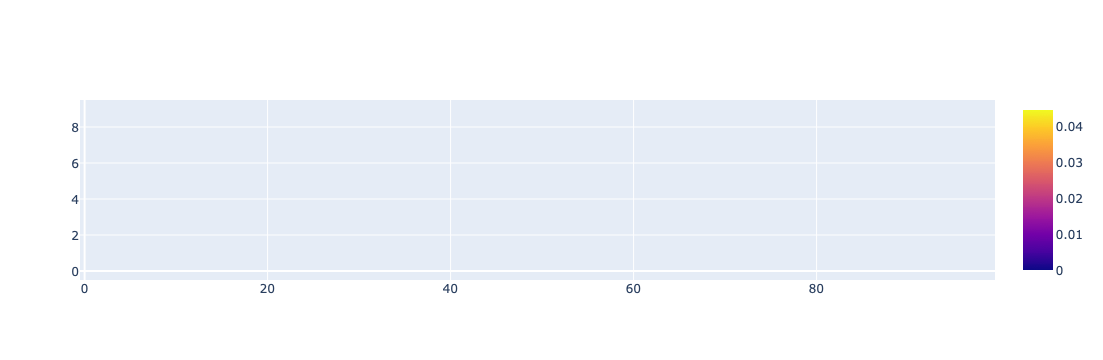

In [127]:
fig_cwt_model = make_subplots(1, 1)
feature = feature_importances
xaxis = data.sample_xaxis

# temp = psf(
#     feature,
#     xaxis=xaxis,
#     fig=fig_cwt,
#     row=1,
#     col=1,
#     xaxis_label=xaxis_label,
#     yaxis_label=yaxis_label,
# )
# temp.plot_cwt(showlegend=False, colorscale="Viridis", showscale=False)


widths = len(feature) / len(xaxis)
widths = int(widths)
temp = feature.reshape(widths, len(xaxis))
fig_cwt_model.add_trace(go.Heatmap(z=temp), row=1, col=1)
fig_cwt_model.update_xaxes(title_text=xaxis_label, row=1, col=1)
fig_cwt_model.update_yaxes(title_text=yaxis_label, row=1, col=1)


fig_cwt_model

In [128]:
print(len(feature_importances))

1000
